## IMPORT LIBRARY

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#202431023_Dezalia Rahmanah Putri

## MEMBACA DATASET

In [2]:
df = pd.read_excel('13_Jumlah_petani_penerima_subsidi_premi_Asuransi_Usaha_Tani_Sapi_AUTS.xlsx',
                  na_values = '-');
df

#202431023_Dezalia Rahmanah Putri

,Provinsi,2018,2019,2020,2021,2022,2023,2019 - 2023
0,Aceh,292.0,188.0,25.0,37.0,NaN,0,542.0
1,Sumatera Utara,4689.0,9630.0,6963.0,3808.0,257.0,0,25347.0
2,Sumatera Barat,5300.0,7593.0,7313.0,4287.0,4438.0,1963,28931.0
3,Riau,1005.0,938.0,1878.0,2354.0,1049.0,220,7224.0
4,Jambi,1038.0,1055.0,859.0,1207.0,1039.0,243,5198.0
5,Sumatera Selatan,1621.0,2458.0,2546.0,1353.0,483.0,182,8461.0
6,Bengkulu,709.0,853.0,37.0,247.0,70.0,0,1916.0
7,Lampung,12170.0,12074.0,9252.0,5229.0,8081.0,1149,46806.0
8,Kep. Bangka Belitung,1474.0,2681.0,1615.0,1079.0,584.0,263,7433.0
9,Kepulauan Riau,53.0,74.0,76.0,NaN,57.0,47,260.0


## EDA 

## ANALISIS DESKRIPTIF

In [3]:
df.head()

#202431023_Dezalia Rahmanah Putri

,Provinsi,2018,2019,2020,2021,2022,2023,2019 - 2023
0,Aceh,292.0,188.0,25.0,37.0,NaN,0,542.0
1,Sumatera Utara,4689.0,9630.0,6963.0,3808.0,257.0,0,25347.0
2,Sumatera Barat,5300.0,7593.0,7313.0,4287.0,4438.0,1963,28931.0
3,Riau,1005.0,938.0,1878.0,2354.0,1049.0,220,7224.0
4,Jambi,1038.0,1055.0,859.0,1207.0,1039.0,243,5198.0


In [4]:
df.shape

#202431023_Dezalia Rahmanah Putri

(34, 8)

In [5]:
df.describe()

#202431023_Dezalia Rahmanah Putri

,2018,2019,2020,2021,2022,2023,2019 - 2023
count,26.000000,28.000000,29.000000,28.000000,27.000000,34.000000,29.000000
mean,3410.500000,5006.785714,4137.931034,3571.464286,2497.629630,588.235294,17803.448276
std,5013.233091,6711.590551,6258.357458,5229.312826,4419.603769,1984.470314,24964.158745
min,37.000000,74.000000,18.000000,22.000000,57.000000,0.000000,161.000000
25%,507.250000,509.250000,810.000000,592.000000,439.000000,0.000000,3084.000000
50%,1186.500000,1331.500000,1615.000000,1516.000000,1049.000000,133.000000,5198.000000
75%,4963.500000,8010.500000,4156.000000,3927.750000,3250.000000,288.500000,25347.000000
max,22347.000000,24846.000000,27414.000000,22266.000000,22453.000000,11563.000000,103702.000000


In [6]:
df.info()

#202431023_Dezalia Rahmanah Putri

<class 'pandas.DataFrame'>
RangeIndex: 34 entries, 0 to 33
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Provinsi     34 non-null     str    
 1   2018         26 non-null     float64
 2   2019         28 non-null     float64
 3   2020         29 non-null     float64
 4   2021         28 non-null     float64
 5   2022         27 non-null     float64
 6   2023         34 non-null     int64  
 7   2019 - 2023  29 non-null     float64
dtypes: float64(6), int64(1), str(1)
memory usage: 2.3 KB


In [7]:
df.isna().sum()
#Dezalia Rahmanah Putri_202431023

Provinsi       0
2018           8
2019           6
2020           5
2021           6
2022           7
2023           0
2019 - 2023    5
dtype: int64

In [8]:
df.duplicated().sum()

#202431023_Dezalia Rahmanah Putri

np.int64(0)

## Pemeriksaan Kualitas Data

In [9]:
fitur = [2018, 2019, 2020, 2021, 2022]
print(f"Sel kosong 2018-2022: {df[fitur].isna().sum().sum()} dari {df[fitur].size} sel ({df[fitur].isna().sum().sum()/df[fitur].size:.1%})")
print('Provinsi kosong total 2018-2022:', df.loc[df[fitur].isna().all(axis=1), 'Provinsi'].tolist())
print('Jumlah provinsi bernilai 0 pada 2023:', (df[2023] == 0).sum())

cek = pd.DataFrame({'Provinsi': df['Provinsi'],
                    'Total_asli': df['2019 - 2023'],
                    'Jumlah_2019_2023': df[[2019, 2020, 2021, 2022, 2023]].sum(axis=1, min_count=1)})
cek['Selisih'] = cek['Total_asli'] - cek['Jumlah_2019_2023']
cek.dropna().head(10)

#202431023_Dezalia Rahmanah Putri

Sel kosong 2018-2022: 32 dari 170 sel (18.8%)
Provinsi kosong total 2018-2022: ['DKI Jakarta', 'Maluku', 'Maluku Utara', 'Papua', 'Papua Barat']
Jumlah provinsi bernilai 0 pada 2023: 13


,Provinsi,Total_asli,Jumlah_2019_2023,Selisih
0,Aceh,542.0,250.0,292.0
1,Sumatera Utara,25347.0,20658.0,4689.0
2,Sumatera Barat,28931.0,25594.0,3337.0
3,Riau,7224.0,6439.0,785.0
4,Jambi,5198.0,4403.0,795.0
5,Sumatera Selatan,8461.0,7022.0,1439.0
6,Bengkulu,1916.0,1207.0,709.0
7,Lampung,46806.0,35785.0,11021.0
8,Kep. Bangka Belitung,7433.0,6222.0,1211.0
9,Kepulauan Riau,260.0,254.0,6.0


## ANALISIS UNIVARIAT & BIVARIAT

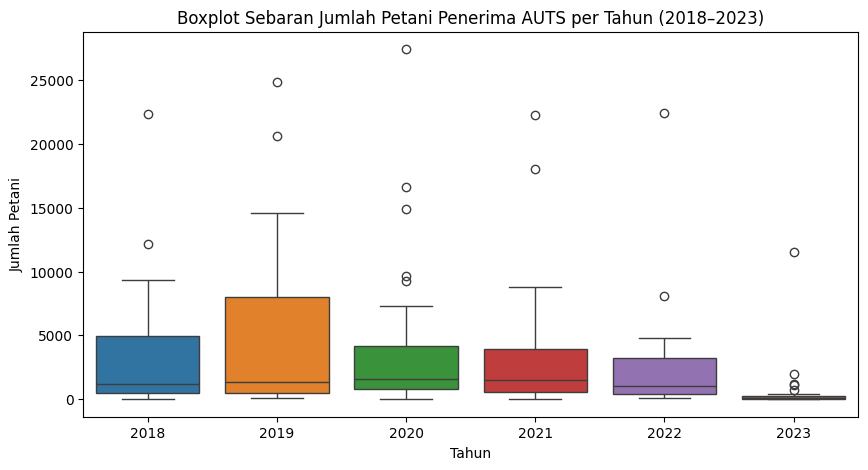

In [10]:
cols_tahun = [2018, 2019, 2020, 2021, 2022, 2023]

plt.figure(figsize=(10, 5))
sns.boxplot(data=df[cols_tahun])

plt.title("Boxplot Sebaran Jumlah Petani Penerima AUTS per Tahun (2018–2023)")
plt.xlabel("Tahun")
plt.ylabel("Jumlah Petani")
plt.show()

#202431023_Dezalia Rahmanah Putri

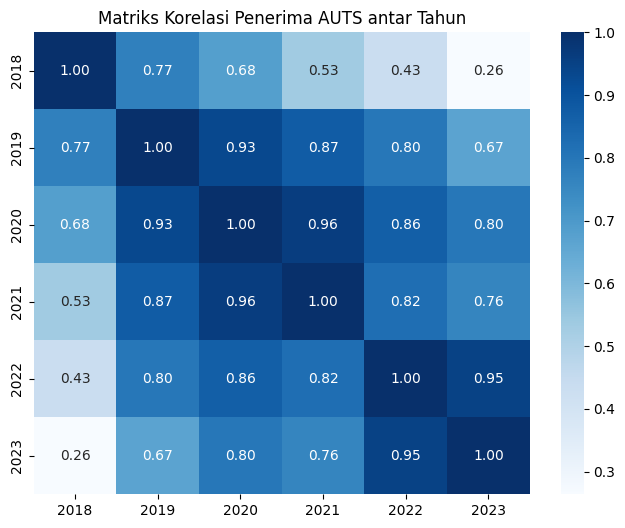

In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[cols_tahun].corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Matriks Korelasi Penerima AUTS antar Tahun')
plt.show()

#202431023_Dezalia Rahmanah Putri

## IDENTIFIKASI OUTLIER MENGGUNAKAN IQR

In [12]:
# Identifikasi Outlier Menggunakan Metode IQR

cols_tahun = [2018, 2019, 2020, 2021, 2022, 2023]

for col in cols_tahun:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    outlier = df[
        (df[col] < batas_bawah) |
        (df[col] > batas_atas)
    ]

    print(f"Tahun {col}")
    print(f"Q1          : {Q1:.2f}")
    print(f"Q3          : {Q3:.2f}")
    print(f"IQR         : {IQR:.2f}")
    print(f"Batas bawah : {batas_bawah:.2f}")
    print(f"Batas atas  : {batas_atas:.2f}")
    print(f"Jumlah outlier: {len(outlier)}")
    print("-" * 30)

##202431023_Dezalia Rahmanah Putri

Tahun 2018
Q1          : 507.25
Q3          : 4963.50
IQR         : 4456.25
Batas bawah : -6177.12
Batas atas  : 11647.88
Jumlah outlier: 2
------------------------------
Tahun 2019
Q1          : 509.25
Q3          : 8010.50
IQR         : 7501.25
Batas bawah : -10742.62
Batas atas  : 19262.38
Jumlah outlier: 2
------------------------------
Tahun 2020
Q1          : 810.00
Q3          : 4156.00
IQR         : 3346.00
Batas bawah : -4209.00
Batas atas  : 9175.00
Jumlah outlier: 5
------------------------------
Tahun 2021
Q1          : 592.00
Q3          : 3927.75
IQR         : 3335.75
Batas bawah : -4411.62
Batas atas  : 8931.38
Jumlah outlier: 2
------------------------------
Tahun 2022
Q1          : 439.00
Q3          : 3250.00
IQR         : 2811.00
Batas bawah : -3777.50
Batas atas  : 7466.50
Jumlah outlier: 2
------------------------------
Tahun 2023
Q1          : 0.00
Q3          : 288.50
IQR         : 288.50
Batas bawah : -432.75
Batas atas  : 721.25
Jumlah outlier: 5
--------------

## PREPROCESSING

### Mengahpus NaN

In [13]:
cols_tahun = [2018, 2019, 2020, 2021, 2022, 2023]

#202431023_Dezalia Rahmanah Putri

In [14]:
df = df.dropna(subset = cols_tahun)

#202431023_Dezalia Rahmanah Putri

In [15]:
print('Jumlah data setelah dropna:', df.shape[0], 'baris')

#202431023_Dezalia Rahmanah Putri

Jumlah data setelah dropna: 24 baris


In [16]:
df.isna().sum()

#202431023_Dezalia Rahmanah Putri

Provinsi       0
2018           0
2019           0
2020           0
2021           0
2022           0
2023           0
2019 - 2023    0
dtype: int64

## PEMISAHAN VARIABLE X dan Y

In [17]:
# Regresi linear, satu variabel bebas (2022) untuk memprediksi 2023
X = df[[2022]]   
y = df[2023]
##
print('Bentuk X:', X.shape, 'Bentuk y:', y.shape)

#Dezalia Rahmanah Putri_202431023

Bentuk X: (24, 1) Bentuk y: (24,)


## MODEL REGRESI

## IMPORT LIBRARY REGRESI

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

#202431023_Dezalia Rahmanah Putri

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=0.25,
                                                    random_state=42)

print(f"Jumlah sampel Data Latih (X_train): {X_train.shape[0]}")
print(f"Jumlah sampel Data Uji (X_test)  : {X_test.shape[0]}")

#202431023_Dezalia Rahmanah Putri

Jumlah sampel Data Latih (X_train): 18
Jumlah sampel Data Uji (X_test)  : 6


## MELATIH MODEL

In [20]:
model = LinearRegression()
model.fit(X_train, y_train)

#202431023_Dezalia Rahmanah Putri

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.49]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-482.2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[21729.54]


In [21]:
print(f"Persamaan regresi: y = {model.intercept_:.2f} + {model.coef_[0]:.4f} * x")
print(f"R2 pada data latih = {model.score(X_train, y_train):.4f}")

#202431023_Dezalia Rahmanah Putri

Persamaan regresi: y = -482.18 + 0.4898 * x
R2 pada data latih = 0.9187


### EVALUASI MODEL

In [22]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

#202431023_Dezalia Rahmanah Putri

In [23]:
y_pred = model.predict(X_test)
y_pred

#202431023_Dezalia Rahmanah Putri

array([1332.19084877, -358.25099554, -356.2916309 ,  -15.85202447,
       1873.46533094, 1164.17533077])

In [24]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE)     : {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R² Score)          : {r2:.4f}")

#202431023_Dezalia Rahmanah Putri

Mean Absolute Error (MAE)     : 514.87
Root Mean Squared Error (RMSE): 558.57
R-squared (R² Score)          : -0.9063


## VISUALISASI PERBANDINGAN

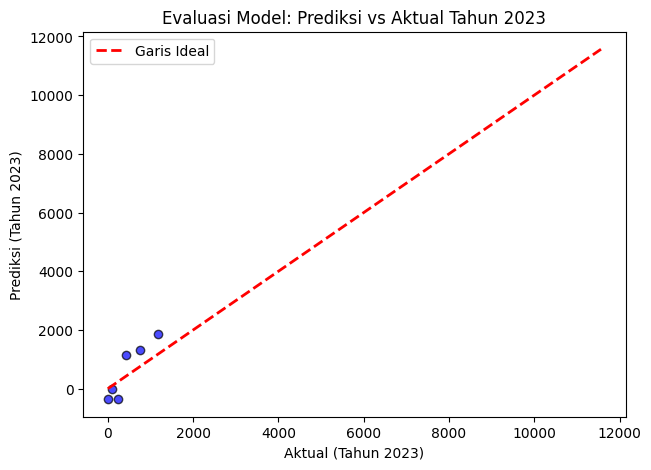

In [25]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, color='blue', alpha=0.7, edgecolors='k')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Garis Ideal')
plt.xlabel('Aktual (Tahun 2023)')
plt.ylabel('Prediksi (Tahun 2023)')
plt.title('Evaluasi Model: Prediksi vs Aktual Tahun 2023')
plt.legend()
plt.show()

#202431023_Dezalia Rahmanah Putri

## MODEL SELURUH DATA & GARIS REGRESI

Persamaan: y = -493.29 + 0.4796 * x
R2 pada seluruh data = 0.9058
Korelasi 2022 vs 2023 = 0.9518


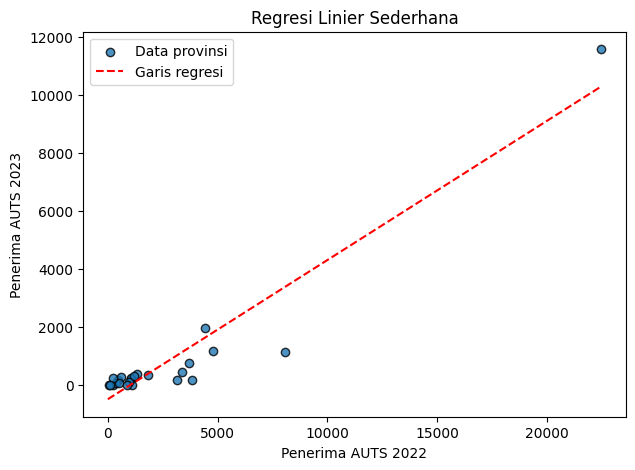

In [26]:
model_final = LinearRegression().fit(X, y)
print(f"Persamaan: y = {model_final.intercept_:.2f} + {model_final.coef_[0]:.4f} * x")
print(f"R2 pada seluruh data = {model_final.score(X, y):.4f}")
print(f"Korelasi 2022 vs 2023 = {df[2022].corr(df[2023]):.4f}")

xs = np.linspace(0, X[2022].max(), 50)
plt.figure(figsize=(7, 5))
plt.scatter(X[2022], y, edgecolors='k', alpha=0.8, label='Data provinsi')
plt.plot(xs, model_final.intercept_ + model_final.coef_[0] * xs, 'r--', label='Garis regresi')
plt.xlabel('Penerima AUTS 2022'); plt.ylabel('Penerima AUTS 2023')
plt.title('Regresi Linier Sederhana'); plt.legend(); plt.show()


#202431023_Dezalia Rahmanah Putri

## VERIFIKASI PERHITUNGAN MANUAL (SOAL 2)

In [27]:
s = df.head(15)
x15, y15 = s[2022], s[2023]
b1 = ((x15 - x15.mean()) * (y15 - y15.mean())).sum() / ((x15 - x15.mean())**2).sum()
b0 = y15.mean() - b1 * x15.mean()
pred15 = b0 + b1 * x15

print(f"b1 = {b1:.5f} | b0 = {b0:.2f}")
print(f"R2 = {r2_score(y15, pred15):.4f}")
print(f"MAE = {mean_absolute_error(y15, pred15):.2f}")
print(f"RMSE = {np.sqrt(mean_squared_error(y15, pred15)):.2f}")
print(f"Prediksi X=1000: {b0 + b1*1000:.2f}")\


#202431023_Dezalia Rahmanah Putri

b1 = 0.18207 | b0 = 56.94
R2 = 0.5761
MAE = 207.87
RMSE = 351.57
Prediksi X=1000: 239.01
